> **DEPRECATED - do not use for the paper.** This notebook augments train/valid/**test** images offline *before* training, which leaks near-copies of test images into training and inflates accuracy (the same flaw as the reference paper). Augmentation is now done online, on the training split only (`src/augmentation.py`). The offline scheme is kept only to reproduce the reference protocol in the leakage study (`data.split_protocol=aug_then_split`).

Expaadning the dataset

---



In [1]:
# Cell 1: Setup for Google Colab
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
from tqdm import tqdm

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Set base path on Google Drive
BASE_PATH = '/content/drive/MyDrive/Kidney_stone_research'
os.makedirs(BASE_PATH, exist_ok=True)

print("✅ Google Drive mounted!")
print(f"📁 Base path: {BASE_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
✅ Google Drive mounted!
📁 Base path: /content/drive/MyDrive/Kidney_stone_research


In [2]:
# Cell 3: Setup Kaggle Credentials
# SECURITY: never hard-code API keys in notebooks. Upload your kaggle.json
# (Kaggle -> Settings -> API -> Create New Token) or set KAGGLE_USERNAME / KAGGLE_KEY.
import shutil

DATA_PATH = os.path.join(BASE_PATH, 'data')
os.makedirs(DATA_PATH, exist_ok=True)
os.makedirs('/root/.kaggle', exist_ok=True)
if os.path.exists(os.path.join(BASE_PATH, 'kaggle.json')):
    shutil.copy(os.path.join(BASE_PATH, 'kaggle.json'), '/root/.kaggle/kaggle.json')
    !chmod 600 /root/.kaggle/kaggle.json
print('Kaggle credentials configured (file or environment variables).')


In [3]:
# Cell 3: Download Datasets from Kaggle
print("📥 Downloading Dataset 1 (Kidney Stone Images)...")
!kaggle datasets download -d safurahajiheidari/kidney-stone-images -p {DATA_PATH}/

print("\n📥 Downloading Dataset 2 (CT Kidney Dataset)...")
!kaggle datasets download -d nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone -p {DATA_PATH}/

# Unzip datasets
print("\n📦 Extracting Dataset 1...")
!unzip -q -o {DATA_PATH}/kidney-stone-images.zip -d {DATA_PATH}/dataset1

print("📦 Extracting Dataset 2...")
!unzip -q -o {DATA_PATH}/ct-kidney-dataset-normal-cyst-tumor-and-stone.zip -d {DATA_PATH}/dataset2

# Clean up zip files
!rm -f {DATA_PATH}/*.zip

print("\n✅ Datasets downloaded and extracted!")

📥 Downloading Dataset 1 (Kidney Stone Images)...
Dataset URL: https://www.kaggle.com/datasets/safurahajiheidari/kidney-stone-images
License(s): other
  0% 0.00/21.1M [00:00<?, ?B/s]
100% 21.1M/21.1M [00:00<00:00, 361MB/s]

📥 Downloading Dataset 2 (CT Kidney Dataset)...
Dataset URL: https://www.kaggle.com/datasets/nazmul0087/ct-kidney-dataset-normal-cyst-tumor-and-stone
License(s): copyright-authors
 98% 1.49G/1.52G [00:09<00:00, 162MB/s]
100% 1.52G/1.52G [00:09<00:00, 173MB/s]

📦 Extracting Dataset 1...
📦 Extracting Dataset 2...

✅ Datasets downloaded and extracted!


In [4]:
# Cell 4: Set All Paths
DATASET1_PATH = os.path.join(DATA_PATH, 'dataset1')
DATASET2_PATH = os.path.join(DATA_PATH, 'dataset2', 'CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone', 'CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone')
RESULTS_DIR = os.path.join(BASE_PATH, 'results')
AUGMENTED_DIR = os.path.join(BASE_PATH, 'augmented_data')

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(AUGMENTED_DIR, exist_ok=True)

# Verify paths
print("🔍 Verifying paths...")
print(f"   Dataset 1: {os.path.exists(DATASET1_PATH)} ✅" if os.path.exists(DATASET1_PATH) else f"   Dataset 1: ❌")
print(f"   Dataset 2: {os.path.exists(DATASET2_PATH)} ✅" if os.path.exists(DATASET2_PATH) else f"   Dataset 2: ❌")

# Show contents
if os.path.exists(DATASET1_PATH):
    print(f"\n📁 Dataset 1 contents: {os.listdir(DATASET1_PATH)}")
if os.path.exists(DATASET2_PATH):
    print(f"📁 Dataset 2 classes: {os.listdir(DATASET2_PATH)}")

print("\n✅ All paths configured!")

🔍 Verifying paths...
   Dataset 1: True ✅
   Dataset 2: True ✅

📁 Dataset 1 contents: ['README.dataset.txt', 'README.roboflow.txt', 'data.yaml', 'test', 'train', 'valid']
📁 Dataset 2 classes: ['Cyst', 'Normal', 'Stone', 'Tumor']

✅ All paths configured!


In [5]:
def augment_rotation(image,angle):
  h,w= image.shape[:2]
  center= (w // 2, h // 2)
  matrix=cv2.getRotationMatrix2D(center,angle,1.0)
  rotated=cv2.warpAffine(image,matrix,(w,h),borderMode=cv2.BORDER_REFLECT )
  return rotated

def augment_flip_horizontal(image):
  return cv2.flip(image,1)

def augment_flip_vertical(image):
  return cv2.flip(image,0)

def augment_brightness(image,factor):
  hsv=cv2.cvtColor(image,cv2.COLOR_BGR2HSV)
  hsv=hsv.astype(np.float32)
  hsv[:,:,2]=np.clip(hsv[:,:,2]*factor,0,255)
  hsv=hsv.astype(np.uint8)
  return cv2.cvtColor(hsv,cv2.COLOR_HSV2BGR)

def augment_contrast(image,factor):
  mean=np.mean(image)
  adjusted=np.clip((image-mean)*factor+mean,0,255)
  return adjusted.astype(np.uint8)

def augment_gaussian_noise(image,mean=0,sigma=25):
  noise=np.random.normal(mean,sigma,image.shape).astype(np.float32)
  noisy=np.clip(image.astype(np.float32)+noise,0,255)
  return noisy.astype(np.uint8)

def augment_blur(image, kernel_size=5):
    """
    Apply Gaussian blur.
    WHY: Some CT images may be slightly blurry.
    """
    return cv2.GaussianBlur(image, (kernel_size, kernel_size), 0)


def augment_sharpen(image):
    """
    Sharpen the image.
    WHY: Enhances edges, opposite of blur augmentation.
    """
    kernel = np.array([[-1, -1, -1],
                       [-1,  9, -1],
                       [-1, -1, -1]])
    return cv2.filter2D(image, -1, kernel)

def augment_zoom(image, zoom_factor=1.2):
    """
    Zoom into center of image.
    WHY: Simulates different scan distances.
    """
    h, w = image.shape[:2]

    # Calculate crop region
    new_h, new_w = int(h / zoom_factor), int(w / zoom_factor)
    start_h, start_w = (h - new_h) // 2, (w - new_w) // 2

    # Crop and resize back
    cropped = image[start_h:start_h+new_h, start_w:start_w+new_w]
    zoomed = cv2.resize(cropped, (w, h))
    return zoomed


def augment_translate(image, tx, ty):
    """
    Shift image by tx, ty pixels.
    WHY: Kidney position varies in different scans.
    """
    h, w = image.shape[:2]
    matrix = np.float32([[1, 0, tx], [0, 1, ty]])
    translated = cv2.warpAffine(image, matrix, (w, h), borderMode=cv2.BORDER_REFLECT)
    return translated

def augment_elastic_transform(image, alpha=50, sigma=5):
    """
    Apply elastic deformation.
    WHY: Simulates tissue deformation, very effective for medical images.
    """
    random_state = np.random.RandomState(None)
    shape = image.shape[:2]

    dx = cv2.GaussianBlur((random_state.rand(*shape) * 2 - 1).astype(np.float32),
                          (0, 0), sigma) * alpha
    dy = cv2.GaussianBlur((random_state.rand(*shape) * 2 - 1).astype(np.float32),
                          (0, 0), sigma) * alpha

    x, y = np.meshgrid(np.arange(shape[1]), np.arange(shape[0]))
    map_x = (x + dx).astype(np.float32)
    map_y = (y + dy).astype(np.float32)

    return cv2.remap(image, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT)


def augment_histogram_equalization(image):
    """
    Apply histogram equalization.
    WHY: Normalizes image intensity distribution.
    """
    if len(image.shape) == 3:
        # Convert to YUV, equalize Y channel, convert back
        yuv = cv2.cvtColor(image, cv2.COLOR_BGR2YUV)
        yuv[:, :, 0] = cv2.equalizeHist(yuv[:, :, 0])
        return cv2.cvtColor(yuv, cv2.COLOR_YUV2BGR)
    else:
        return cv2.equalizeHist(image)


def augment_clahe(image, clip_limit=2.0):
    """
    Apply CLAHE (Contrast Limited Adaptive Histogram Equalization).
    WHY: Better than regular histogram eq. for medical images.
    """
    if len(image.shape) == 3:
        lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
        clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8))
        lab[:, :, 0] = clahe.apply(lab[:, :, 0])
        return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)
    else:
        clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=(8, 8))
        return clahe.apply(image)



print("✅ Defined 12 augmentation functions!")
print("   - Rotation, Flip (H/V), Brightness, Contrast")
print("   - Noise, Blur, Sharpen, Zoom, Translate")
print("   - Elastic Transform, Histogram Eq., CLAHE")

✅ Defined 12 augmentation functions!
   - Rotation, Flip (H/V), Brightness, Contrast
   - Noise, Blur, Sharpen, Zoom, Translate
   - Elastic Transform, Histogram Eq., CLAHE


In [6]:
#creating pipeline of augmenation
def get_all_augmentations(image):
  # ereturn slist of augmentedimg and augmentetion name tuples
  augmented=[]

  # original
  augmented.append((image.copy(),'original'))

  # 1-4 rotations
  augmented.append((augment_rotation(image,90),'rotate_90'))
  augmented.append((augment_rotation(image,180),'rotate_180'))
  augmented.append((augment_rotation(image,270),'rotate_270'))
  augmented.append((augment_rotation(image,45),'rotate_45'))

  # 5-6 flips
  augmented.append((augment_flip_horizontal(image),'flip_hor'))
  augmented.append((augment_flip_vertical(image),'flip_ver'))

  # 7-8 birghtness
  augmented.append((augment_brightness(image,1.3),'bright_up'))
  augmented.append((augment_brightness(image,0.7),'contrast_down'))

  # 9-10 contrast

  augmented.append((augment_contrast(image,1.3),'contrast_up'))
  augmented.append((augment_contrast(image,0.7),'contrast_down'))

  # 11: Gaussian noise
  augmented.append((augment_gaussian_noise(image), 'noise'))

  # 12-13: Blur and Sharpen
  augmented.append((augment_blur(image, 5), 'blur'))
  augmented.append((augment_sharpen(image), 'sharpen'))

  # 14-15: Zoom
  augmented.append((augment_zoom(image, 1.2), 'zoom_in'))
  augmented.append((augment_zoom(image, 0.8), 'zoom_out'))

  # 16-19: Translations
  augmented.append((augment_translate(image, 20, 0), 'translate_right'))
  augmented.append((augment_translate(image, -20, 0), 'translate_left'))
  augmented.append((augment_translate(image, 0, 20), 'translate_down'))
  augmented.append((augment_translate(image, 0, -20), 'translate_up'))

  # 20: Elastic transform
  augmented.append((augment_elastic_transform(image), 'elastic'))

  # 21: CLAHE
  augmented.append((augment_clahe(image), 'clahe'))

  return augmented


print("Augmentation pipeline ready")


Augmentation pipeline ready


📸 Sample image: 1-3-46-670589-33-1-63700700749865510700001-5062181...
Generated 22 augmented versions
💾 Saved to /content/drive/MyDrive/Kidney_stone_research/results/augmentation_visualisation.png


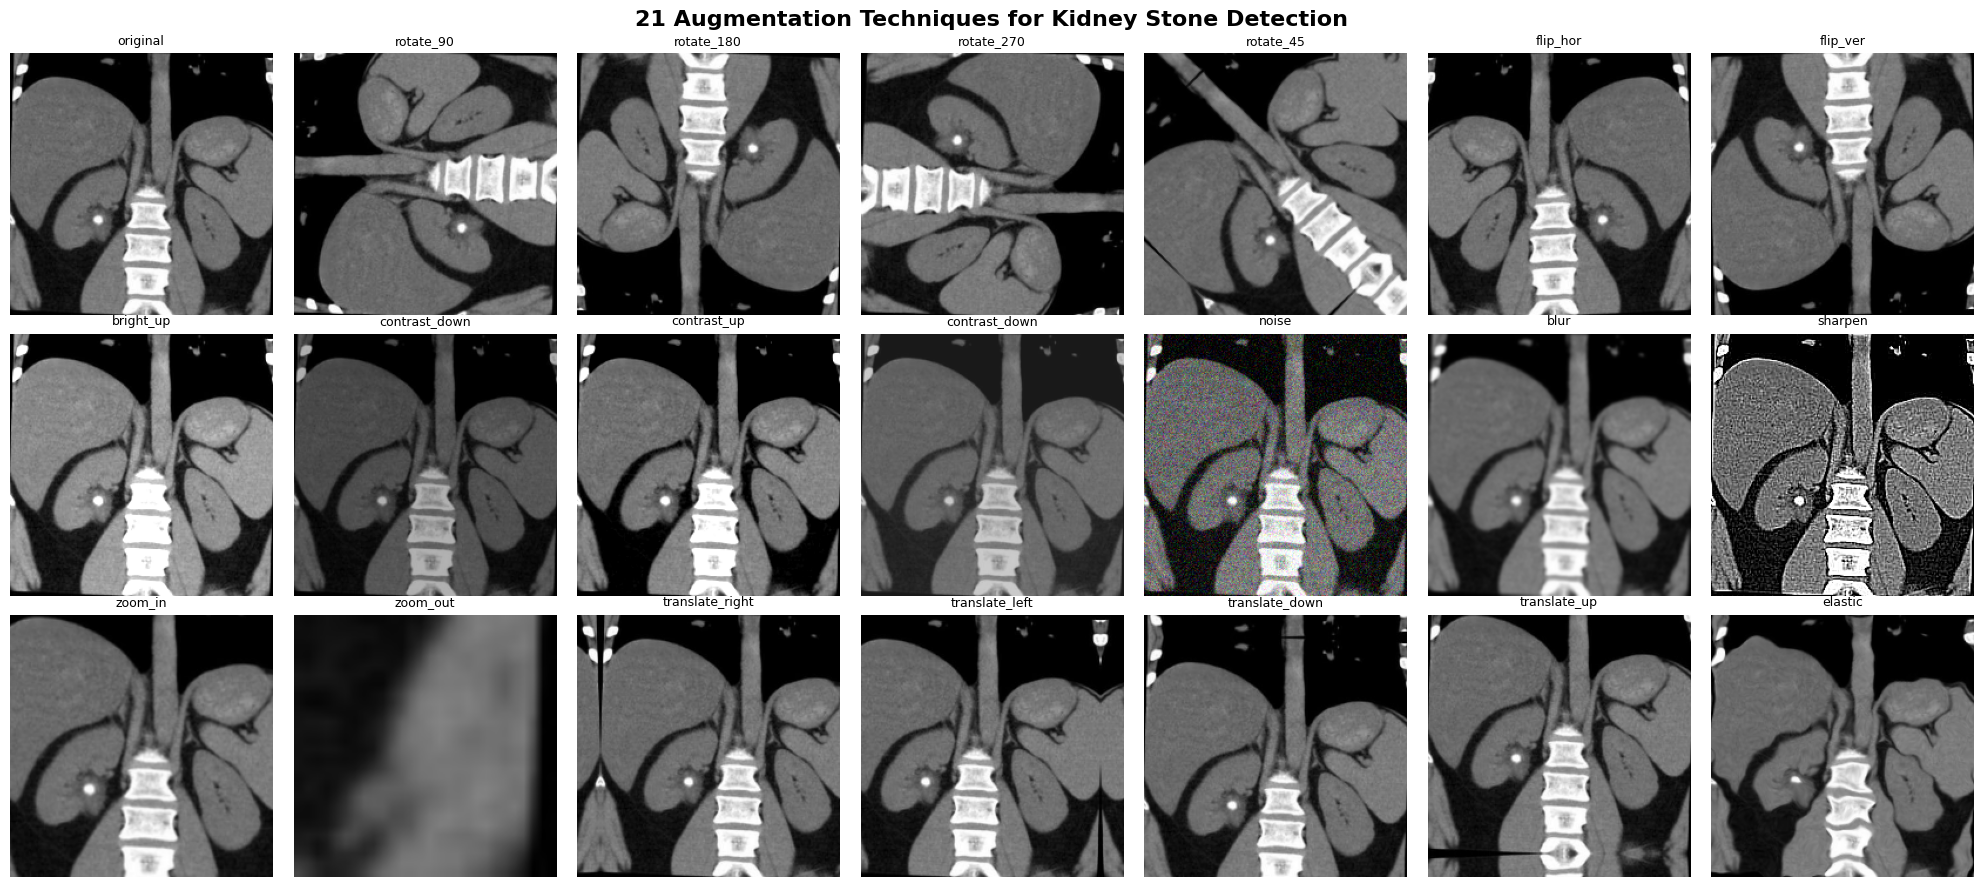

In [7]:
# Cell 7: Visualize Augmentations
def visualise_augmentations(image_path):
    image = cv2.imread(image_path)
    if image is None:
        print(f"Could not load {image_path}")
        return
    image = cv2.resize(image, (224, 224))

    augmented = get_all_augmentations(image)

    print(f"Generated {len(augmented)} augmented versions")

    fig, axes = plt.subplots(3, 7, figsize=(20, 9))
    fig.suptitle("21 Augmentation Techniques for Kidney Stone Detection", fontsize=16, fontweight='bold')

    for idx, (ax, (aug_img, name)) in enumerate(zip(axes.flat, augmented)):
        if len(aug_img.shape) == 3:
            ax.imshow(cv2.cvtColor(aug_img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(aug_img, cmap='gray')
        ax.set_title(name, fontsize=9)
        ax.axis('off')

    plt.tight_layout()
    save_path = os.path.join(RESULTS_DIR, 'augmentation_visualisation.png')
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    print(f"💾 Saved to {save_path}")
    plt.show()


# Find a sample image and visualize
train_images = os.path.join(DATASET1_PATH, 'train', 'images')

if os.path.exists(train_images):
    files_list = os.listdir(train_images)
    image_files = [f for f in files_list if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
    
    if image_files:
        sample_path = os.path.join(train_images, image_files[0])
        print(f"📸 Sample image: {os.path.basename(sample_path)[:50]}...")
        visualise_augmentations(sample_path)
    else:
        print("❌ No image files found in train/images folder")
else:
    print(f"❌ Path not found: {train_images}")

In [8]:
# Dataset 1 augmentation

def augment_dataset(input_dir,output_dir,augment_factor=21):
    # augment all images in a directory
    os.makedirs(output_dir,exist_ok=True)
    # get all images
    image_files=[f for f in os.listdir(input_dir)
                 if f.lower().endswith(('.png','.jpg','.jpeg'))]
    
    print(f"found {len(image_files)} images")
    
    total_created=0
    
    for img_file in tqdm(image_files,desc="Augmenting"):
        img_path=os.path.join(input_dir,img_file)
        image=cv2.imread(img_path)
        
        if image is None:
            continue
        
        # resizing
        image=cv2.resize(image,(224,224))
        augmented=get_all_augmentations(image)[:augment_factor]
        
        base_name=os.path.splitext(img_file)[0]
        
        for aug_img,aug_name in augmented:
            output_name=f"{base_name}_{aug_name}.jpg"
            output_path=os.path.join(output_dir,output_name)
            cv2.imwrite(output_path,aug_img)
            total_created+=1
            
    print(f"Created {total_created} augmented images")
    print(f"saved to {output_dir}")
    
    return total_created
        
        
        
print("=" * 60)
print("AUGMENTING DATASET 1")
print("=" * 60)

DATASET1_AUG = os.path.join(AUGMENTED_DIR, 'dataset1')

for split in ['train', 'valid', 'test']:
    input_path = os.path.join(DATASET1_PATH, split, 'images')
    output_path = os.path.join(DATASET1_AUG, split)
    
    if os.path.exists(input_path):
        print(f"\n📂 Processing {split}...")
        augment_dataset(input_path, output_path, augment_factor=21)
    else:
        print(f"⚠️ {split}/images not found, skipping...")

print("\n✅ Dataset 1 augmentation complete!")
        

AUGMENTING DATASET 1

📂 Processing train...
found 1054 images


Augmenting: 100%|██████████| 1054/1054 [04:25<00:00,  3.96it/s]


Created 22134 augmented images
saved to /content/drive/MyDrive/Kidney_stone_research/augmented_data/dataset1/train

📂 Processing valid...
found 123 images


Augmenting: 100%|██████████| 123/123 [00:30<00:00,  4.06it/s]


Created 2583 augmented images
saved to /content/drive/MyDrive/Kidney_stone_research/augmented_data/dataset1/valid

📂 Processing test...
found 123 images


Augmenting: 100%|██████████| 123/123 [00:30<00:00,  4.07it/s]

Created 2583 augmented images
saved to /content/drive/MyDrive/Kidney_stone_research/augmented_data/dataset1/test

✅ Dataset 1 augmentation complete!


In [9]:
# ============================================
# AUGMENT DATASET 2
# ============================================
print("=" * 60)
print("AUGMENTING DATASET 2")
print("=" * 60)

DATASET2_AUG = os.path.join(AUGMENTED_DIR, 'dataset2')

if os.path.exists(DATASET2_PATH):
    print(f"✅ Found Dataset 2 at: {DATASET2_PATH}")
    
    # Get class folders (Cyst, Normal, Stone, Tumor)
    class_folders = [f for f in os.listdir(DATASET2_PATH) 
                     if os.path.isdir(os.path.join(DATASET2_PATH, f))]
    
    print(f"📁 Classes found: {class_folders}")
    
    for class_name in class_folders:
        input_path = os.path.join(DATASET2_PATH, class_name)
        output_path = os.path.join(DATASET2_AUG, class_name)
        
        print(f"\n📂 Processing class: {class_name}")
        
        # Use 5x augmentation for Dataset 2 (already large)
        augment_dataset(input_path, output_path, augment_factor=5)
    
    print("\n✅ Dataset 2 augmentation complete!")
else:
    print(f"❌ Dataset 2 not found at: {DATASET2_PATH}")

AUGMENTING DATASET 2
✅ Found Dataset 2 at: /content/drive/MyDrive/Kidney_stone_research/data/dataset2/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone/CT-KIDNEY-DATASET-Normal-Cyst-Tumor-Stone
📁 Classes found: ['Cyst', 'Normal', 'Stone', 'Tumor']

📂 Processing class: Cyst
found 3709 images


Augmenting: 100%|██████████| 3709/3709 [05:24<00:00, 11.42it/s]


Created 18545 augmented images
saved to /content/drive/MyDrive/Kidney_stone_research/augmented_data/dataset2/Cyst

📂 Processing class: Normal
found 5077 images


Augmenting: 100%|██████████| 5077/5077 [08:28<00:00,  9.99it/s]


Created 25385 augmented images
saved to /content/drive/MyDrive/Kidney_stone_research/augmented_data/dataset2/Normal

📂 Processing class: Stone
found 1377 images


Augmenting: 100%|██████████| 1377/1377 [02:18<00:00,  9.94it/s]


Created 6885 augmented images
saved to /content/drive/MyDrive/Kidney_stone_research/augmented_data/dataset2/Stone

📂 Processing class: Tumor
found 2283 images


Augmenting: 100%|██████████| 2283/2283 [04:01<00:00,  9.47it/s]

Created 11415 augmented images
saved to /content/drive/MyDrive/Kidney_stone_research/augmented_data/dataset2/Tumor

✅ Dataset 2 augmentation complete!


In [10]:


def count_images(path):
    """Count all images in a directory recursively."""
    count = 0
    if not os.path.exists(path):
        return 0
    for root, dirs, files in os.walk(path):
        for f in files:
            if f.lower().endswith(('.png', '.jpg', '.jpeg')):
                count += 1
    return count


print("=" * 60)
print("📊 AUGMENTATION SUMMARY")
print("=" * 60)

# Original counts
print("\n📁 ORIGINAL DATASET SIZES:")
orig1 = count_images(DATASET1_PATH)
orig2 = count_images(DATASET2_PATH)
print(f"   Dataset 1: {orig1:,} images")
print(f"   Dataset 2: {orig2:,} images")
print(f"   Total:     {orig1 + orig2:,} images")

# Augmented counts
print("\n📁 AUGMENTED DATASET SIZES:")
aug1 = count_images(os.path.join(AUGMENTED_DIR, 'dataset1'))
aug2 = count_images(os.path.join(AUGMENTED_DIR, 'dataset2'))
print(f"   Dataset 1: {aug1:,} images")
print(f"   Dataset 2: {aug2:,} images")
print(f"   Total:     {aug1 + aug2:,} images")

# Expansion ratio
print("\n📈 EXPANSION RATIOS:")
if orig1 > 0:
    print(f"   Dataset 1: {aug1/orig1:.1f}x expansion")
if orig2 > 0:
    print(f"   Dataset 2: {aug2/orig2:.1f}x expansion")

print("\n✅ Ready for model training!")

📊 AUGMENTATION SUMMARY

📁 ORIGINAL DATASET SIZES:
   Dataset 1: 1,300 images
   Dataset 2: 12,446 images
   Total:     13,746 images

📁 AUGMENTED DATASET SIZES:
   Dataset 1: 26,000 images
   Dataset 2: 62,230 images
   Total:     88,230 images

📈 EXPANSION RATIOS:
   Dataset 1: 20.0x expansion
   Dataset 2: 5.0x expansion

✅ Ready for model training!


📊 Original distribution: {'Cyst': 3709, 'Normal': 5077, 'Stone': 1377, 'Tumor': 2283}
📊 Augmented distribution: {'Cyst': 18545, 'Normal': 25385, 'Stone': 6885, 'Tumor': 11415}
💾 Saved to: /content/drive/MyDrive/Kidney_stone_research/results/class_distribution.png


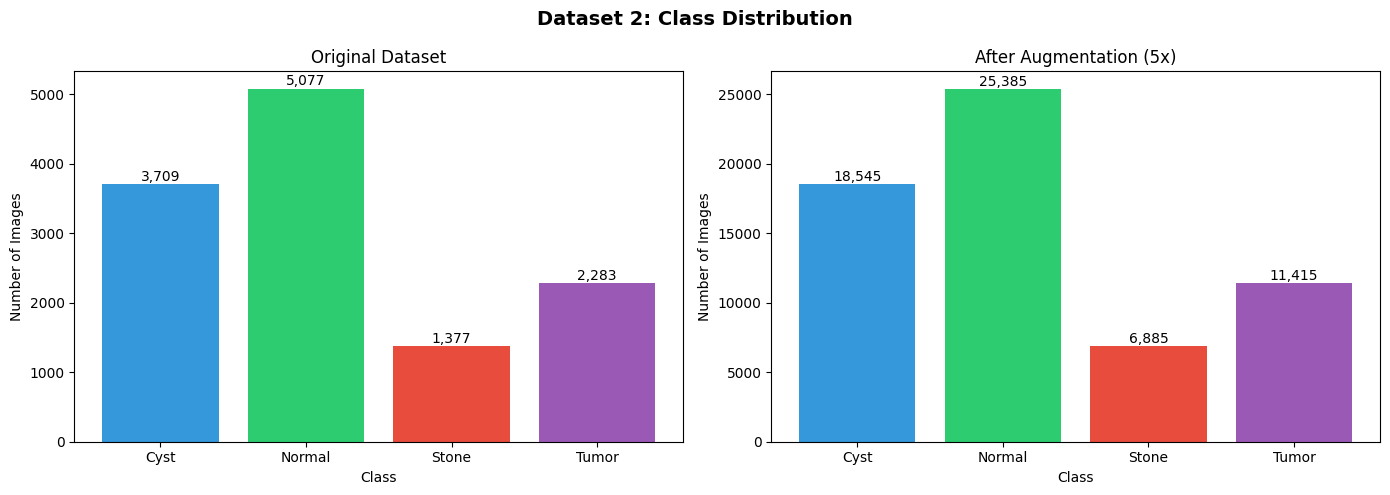

In [11]:
# ============================================
# VISUALIZE CLASS DISTRIBUTION
# ============================================

def get_class_distribution(dataset_path):
    """Get image count per class folder."""
    distribution = {}
    
    if not os.path.exists(dataset_path):
        return distribution
    
    for item in os.listdir(dataset_path):
        item_path = os.path.join(dataset_path, item)
        if os.path.isdir(item_path):
            count = count_images(item_path)
            if count > 0:
                distribution[item] = count
    
    return distribution


# Get distributions
dist_orig = get_class_distribution(DATASET2_PATH)
dist_aug = get_class_distribution(os.path.join(AUGMENTED_DIR, 'dataset2'))

print(f"📊 Original distribution: {dist_orig}")
print(f"📊 Augmented distribution: {dist_aug}")

# Plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Dataset 2: Class Distribution', fontsize=14, fontweight='bold')

# Original
if dist_orig:
    ax1 = axes[0]
    classes = list(dist_orig.keys())
    counts = list(dist_orig.values())
    colors = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'][:len(classes)]
    bars = ax1.bar(classes, counts, color=colors)
    ax1.set_title('Original Dataset')
    ax1.set_ylabel('Number of Images')
    ax1.set_xlabel('Class')
    for bar, count in zip(bars, counts):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 50, 
                 f'{count:,}', ha='center', fontsize=10)
else:
    axes[0].text(0.5, 0.5, 'No data found', ha='center', va='center', fontsize=14)
    axes[0].set_title('Original Dataset - No Data')

# Augmented
if dist_aug:
    ax2 = axes[1]
    classes = list(dist_aug.keys())
    counts = list(dist_aug.values())
    colors = ['#3498db', '#2ecc71', '#e74c3c', '#9b59b6'][:len(classes)]
    bars = ax2.bar(classes, counts, color=colors)
    ax2.set_title('After Augmentation (5x)')
    ax2.set_ylabel('Number of Images')
    ax2.set_xlabel('Class')
    for bar, count in zip(bars, counts):
        ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 200, 
                 f'{count:,}', ha='center', fontsize=10)
else:
    axes[1].text(0.5, 0.5, 'Run Dataset 2 augmentation first', ha='center', va='center', fontsize=12)
    axes[1].set_title('Augmented Dataset - No Data Yet')

plt.tight_layout()
save_path = f'{RESULTS_DIR}/class_distribution.png'
plt.savefig(save_path, dpi=150, bbox_inches='tight')
print(f"💾 Saved to: {save_path}")
plt.show()